In [46]:
"""

Exploring how to plot the gain modulation due to the autapse

1) plot F-inst/steady versus I for each neuron type.


"""

from aqua.batchAQUA_general import batchAQUA
from aqua.AQUA_general import AQUA
from aqua.stimulus import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

import pickle
import random
import seaborn as sns
sns.set_theme(style = 'whitegrid')

from simulation import get_F



In [47]:
# import data
SAVE = True
name = "RS_intHD_uniform"
out_dir = f'.//{name}//'

filename = out_dir + f"{name}_GAIN.pickle"
print()
with open(filename, 'rb') as file:
    df = pickle.load(file)

print(df.keys())
print(df['f'])
print(df['F_instant'])


Index(['e', 'f', 'tau', 'autapse current', 'autapse delay', 'I_h', 'F_instant',
       'F_steady', 'num_frequencies', 'entropy'],
      dtype='object')
0          0.0
1          0.0
2          0.0
3          0.0
4          0.0
         ...  
78195    460.0
78196    460.0
78197    460.0
78198    460.0
78199    460.0
Name: f, Length: 78200, dtype: float64
0              NaN
1              NaN
2              NaN
3              NaN
4              NaN
           ...    
78195    97.087379
78196    88.495575
78197    98.039216
78198    92.592593
78199    85.470085
Name: F_instant, Length: 78200, dtype: float64


6
26
3
[0.  0.2 0.4]
391
- - - 
26


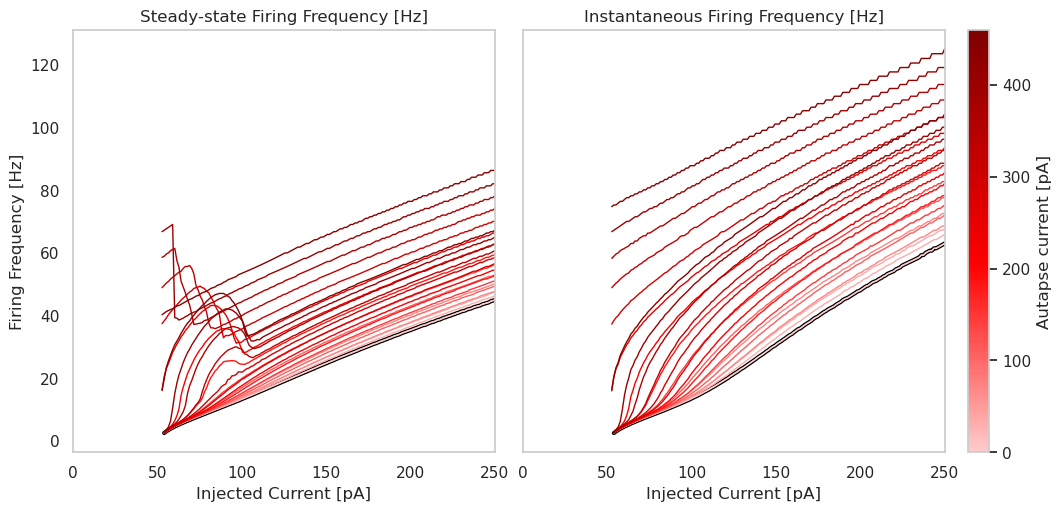

In [48]:
import matplotlib.colors as mcolors

# plot F vs I for each neuron

e_vals = df["e"].unique()
f_vals = df["f"].unique()
tau_vals = df["tau"].unique()

print(len(e_vals))
print(len(f_vals))
print(len(tau_vals))

# two equal-sized main axes plus a narrow colorbar axis at the far right
fig, axs = plt.subplots(1, 3, figsize = (10.5, 5), gridspec_kw = {'width_ratios': [1, 1, 0.05]}, layout = 'constrained')
ax = axs[:2]
cax = axs[2]
ax[1].sharey(ax[0])
ax[1].tick_params(labelleft = False)

e_plot = e_vals[::2]
print(e_plot)
f_plot = f_vals[::2]
tau_plot = np.array([0.])

N_neurons = int(len(df)/len(df['I_h'].unique()))
print(N_neurons)
cmap = plt.get_cmap('seismic')
aut_curr = np.array(df['f'].unique())
print("- - - ")
print(len(aut_curr))
new_colors = cmap(np.linspace(0.55, 1., 256))        # only red colormap
new_cmap = mcolors.LinearSegmentedColormap.from_list('bwr_reds', new_colors)
# map colour by autapse current value (control neuron has NaN and is drawn in black)
norm = mcolors.Normalize(vmin = np.nanmin(aut_curr), vmax = np.nanmax(aut_curr))

for e in e_plot:
    for f in f_plot:
        for tau in tau_plot:
            sub_df = df[(df["e"] == e) & (df["f"] == f) & (df["tau"] == tau)]
            
            if len(sub_df['F_instant']) == 0:
                continue

            if e == 0.0 and f == 0.0 and tau == 0.0:
                colour = (0., 0., 0.)
                linewidth = 3
            else:
                neuron_autapse = sub_df['f'].unique()[0]
                colour = new_cmap(norm(neuron_autapse))
                linewidth = 1
            
            #plot F_steady
            ax[0].plot(sub_df['I_h'], sub_df['F_steady'], c = colour, linewidth = linewidth)
            # plot F_instant
            ax[1].plot(sub_df['I_h'], sub_df['F_instant'], c = colour, linewidth = linewidth)

ax[0].set_xlabel('Injected Current [pA]')
ax[1].set_xlabel('Injected Current [pA]')
ax[0].set_xlim(df.min(axis = 0)['I_h'], df.max(axis = 0)['I_h'])
ax[1].set_xlim(df.min(axis = 0)['I_h'], df.max(axis = 0)['I_h'])
#ax[0].set_xlim(df.min(axis = 0)['I_h'], 200)
#ax[1].set_xlim(df.min(axis = 0)['I_h'], 200)

ax[0].set_ylabel('Firing Frequency [Hz]')

ax[0].set_title("Steady-state Firing Frequency [Hz]")   
ax[1].set_title("Instantaneous Firing Frequency [Hz]")

# remove grids
ax[0].grid(False)
ax[1].grid(False)

# colorbar shared by both axes
fig.colorbar(plt.cm.ScalarMappable(norm = norm, cmap = new_cmap), cax = cax, label = 'Autapse current [pA]')


if SAVE: plt.savefig(out_dir + "I-O_gain_modulation.svg")


ValueError: Index contains duplicate entries, cannot reshape

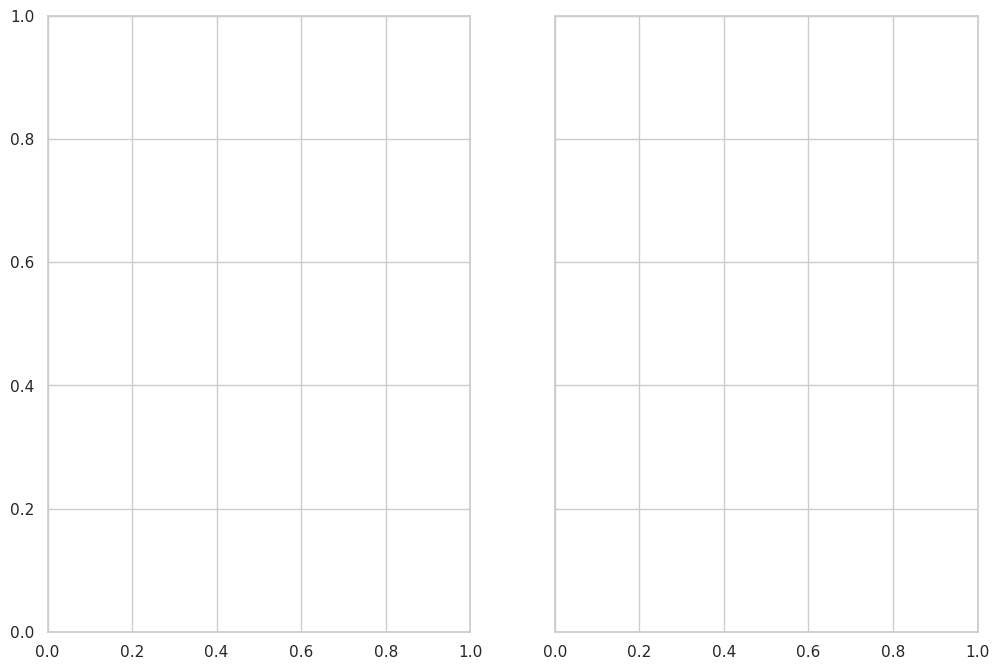

In [49]:
# plot heatmap of F-steady/instant versus autapse current and delay...

"""

From the plots, it seems these metrics might be sufficient to differentiate the different behavioural regimes?
These may serve then as a lower-dimensional interpretation of our results...

"""
from matplotlib.ticker import MultipleLocator
fig, ax = plt.subplots(1, 2, figsize = (12, 8), sharey = True)

temp_df = df.copy()

#temp_df['temp_id'] = temp_df.groupby(['autapse delay', 'I_h']).cumcount()
temp_df = temp_df.round(decimals = 2)
temp_df= temp_df.fillna(0.)


steady_df = (temp_df.pivot(index = ['autapse current', 'autapse delay'], columns = 'I_h', values = 'F_steady'))
instant_df = (temp_df.pivot(index = ['autapse current', 'autapse delay'], columns = 'I_h', values = 'F_instant'))

sns.heatmap(steady_df, annot = False, linewidth = 0., ax = ax[0], xticklabels = 10, yticklabels = 20, cbar_kws = {'label': 'Firing Freq. [Hz]'})
sns.heatmap(instant_df, annot = False, linewidth = 0., ax = ax[1], xticklabels = 10, yticklabels = 20, cbar_kws = {'label': 'Firing Freq. [Hz]'})

#ax[0].yaxis.set_major_locator(MultipleLocator(10))

ax[0].set_xlabel('Step Current [pA]')
ax[1].set_xlabel('Step Current [pA]')

ax[0].set_ylabel('Current through autapse [pA] - mean delay of autapse [ms]')
ax[1].set_ylabel('')

ax[0].set_title('Steady State')
ax[1].set_title('Instantaneous')

fig.suptitle('Firing Frequencies versus net current and mean delay of the autapse ')

#if SAVE: plt.savefig(out_dir + "frequency_by_net_current.svg")

Text(0.5, 0.98, 'Firing Frequencies versus current through the autapse')

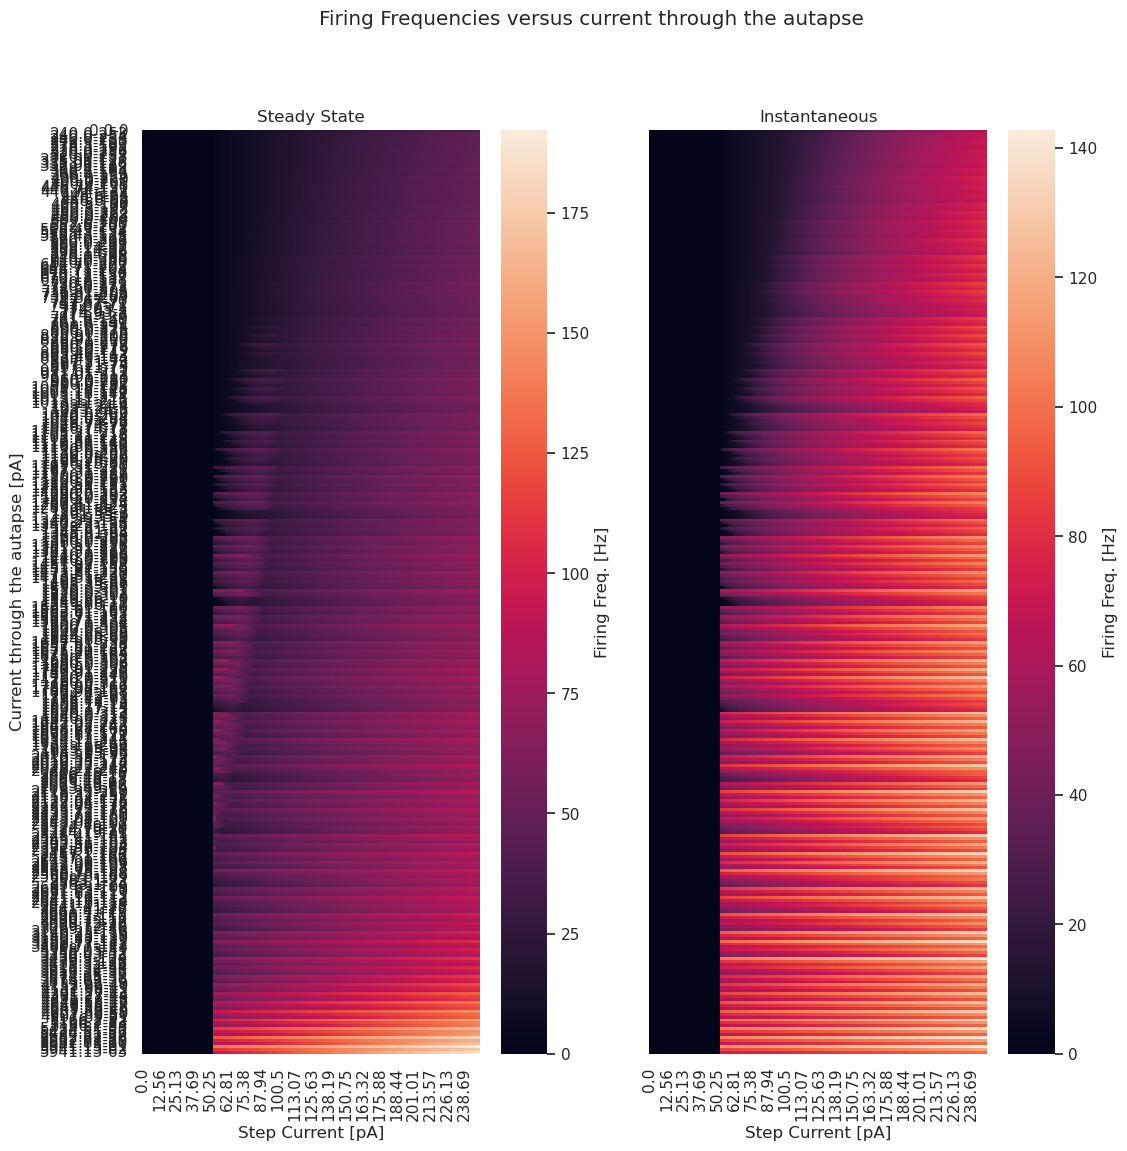

In [ ]:
# plot heatmap of F-steady/instant versus net autapse current

fig, ax = plt.subplots(1, 2, figsize = (12, 12), sharey = True)

temp_df = df.copy()

# supply a unique identifier for each set of autapse parameters
temp_df['temp_id'] = temp_df.groupby(['e', 'f', 'tau']).ngroup()
temp_df = temp_df.round(decimals = 2)
temp_df= temp_df.fillna(0.)


steady_df = (temp_df.pivot(index = ['autapse current', 'temp_id'], columns = 'I_h', values = 'F_steady'))
instant_df = (temp_df.pivot(index = ['autapse current', 'temp_id'], columns = 'I_h', values = 'F_instant'))

sns.heatmap(steady_df, annot = False, linewidth = 0., ax = ax[0], xticklabels = 10, yticklabels = True, cbar_kws = {'label': 'Firing Freq. [Hz]'})
sns.heatmap(instant_df, annot = False, linewidth = 0., ax = ax[1], xticklabels = 10, yticklabels = True, cbar_kws = {'label': 'Firing Freq. [Hz]'})

ax[0].set_xlabel('Step Current [pA]')
ax[1].set_xlabel('Step Current [pA]')

ax[0].set_ylabel('Current through the autapse [pA]')
ax[1].set_ylabel('')

ax[0].set_title('Steady State')
ax[1].set_title('Instantaneous')

fig.suptitle('Firing Frequencies versus current through the autapse')

Text(0.5, 0.98, 'Firing Frequencies versus the mean delay of the autapse')

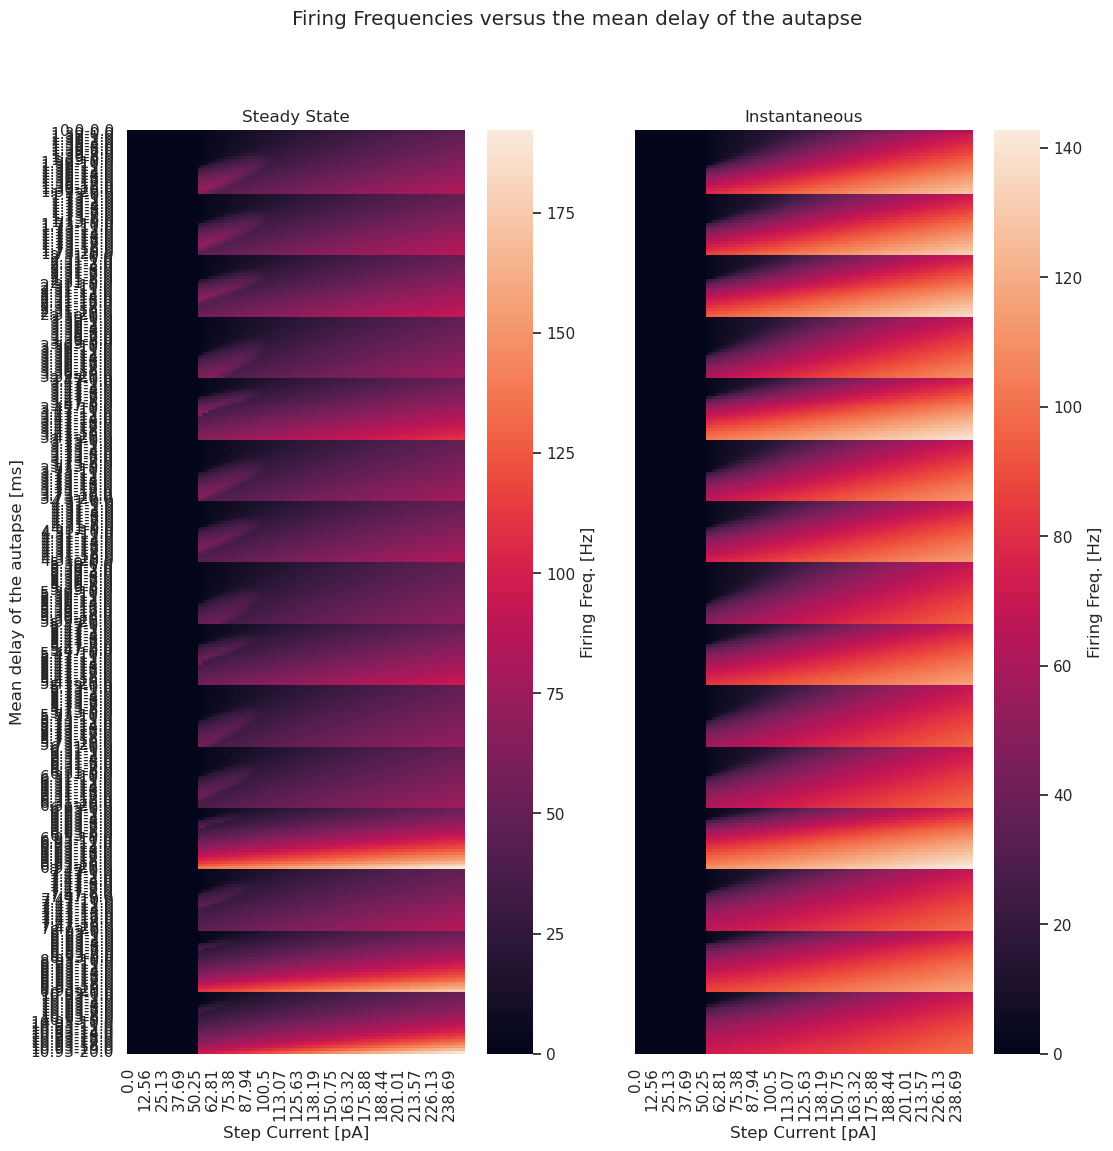

In [ ]:
# plot heatmap of F-steady/instant versus mean autapse delay

fig, ax = plt.subplots(1, 2, figsize = (12, 12), sharey = True)

temp_df = df.copy()

temp_df['temp_id'] = temp_df.groupby(['autapse delay', 'I_h']).cumcount()
temp_df = temp_df.round(decimals = 2)
temp_df= temp_df.fillna(0.)


steady_df = (temp_df.pivot(index = ['autapse delay', 'temp_id'], columns = 'I_h', values = 'F_steady'))
instant_df = (temp_df.pivot(index = ['autapse delay', 'temp_id'], columns = 'I_h', values = 'F_instant'))

sns.heatmap(steady_df, annot = False, linewidth = 0., ax = ax[0], xticklabels = 10, yticklabels = True, cbar_kws = {'label': 'Firing Freq. [Hz]'})
sns.heatmap(instant_df, annot = False, linewidth = 0., ax = ax[1], xticklabels = 10, yticklabels = True, cbar_kws = {'label': 'Firing Freq. [Hz]'})

ax[0].set_xlabel('Step Current [pA]')
ax[1].set_xlabel('Step Current [pA]')

ax[0].set_ylabel('Mean delay of the autapse [ms]')
ax[1].set_ylabel('')

ax[0].set_title('Steady State')
ax[1].set_title('Instantaneous')

fig.suptitle('Firing Frequencies versus the mean delay of the autapse')

### Plotting the traces where there are weird results just above threshold

In [ ]:
"""
Plotting for different tau values where net autapse current is 1500 or 1250

RESULTS: seems to be a range where the neuron exhibits tonic bursting!! Right in the middle of the 
physiological range!

"""


params = df[((df['autapse current'] == 1250.0) | (df['autapse current'] == 1500.0)) & (df['I_h'] == 0.0)]

# INTEGRATOR

RS_int = {'name': 'RS_ref', 'C': 100, 'k': 0.7, 'v_r': -60, 'v_t': -40, 'v_peak': 35,
     'a': 0.03, 'b': -2, 'c': -50, 'd': 100, 'e': 0., 'f': 0., 'tau': 0.}

RS_int_1500 = {'name': 'RS_ref', 'C': 100, 'k': 0.7, 'v_r': -60, 'v_t': -40, 'v_peak': 35,
     'a': 0.03, 'b': -2, 'c': -50, 'd': 100, 'e': 0.1, 'f': 150., 'tau': 0.}
    
RS_int_1250 = {'name': 'RS_ref', 'C': 100, 'k': 0.7, 'v_r': -60, 'v_t': -40, 'v_peak': 35,
     'a': 0.03, 'b': -2, 'c': -50, 'd': 100, 'e': 0.2, 'f': 250., 'tau': 0.}




tau_vals = np.array([0., 0.5, 2.0, 4.0])
params_1500 = []
params_1250 = []

for tau in tau_vals:
    temp_param_1500 = RS_int_1500.copy()
    temp_param_1500['tau'] = tau
    params_1500.append(temp_param_1500)
    
    temp_param_1250 = RS_int_1250.copy()
    temp_param_1250['tau'] = tau
    params_1250.append(temp_param_1250)

df_1500 = pd.DataFrame(params_1500)
df_1250 = pd.DataFrame(params_1250)


T = 1000
dt = 0.1
N_iter = int(T/dt)

batch_1500 = batchAQUA(df_1500)
batch_1250 = batchAQUA(df_1250)

x_start = np.full((len(tau_vals), 3), fill_value = np.array([-60, 0, 0]))
t_start = np.zeros(len(tau_vals))

batch_1500.Initialise(x_start, t_start)
batch_1250.Initialise(x_start, t_start)

# define injected current 
I_h = 65
I_inj = np.array([step_current(N_iter, dt, 0.0, 100, I_h) for tau in tau_vals])

# simulate
X_1500, T, spikes_1500 = batch_1500.update_batch(dt, N_iter, I_inj)
X_1250, T, spikes_1250 = batch_1250.update_batch(dt, N_iter, I_inj)


100%|██████████| 9999/9999 [00:01<00:00, 7910.96it/s]


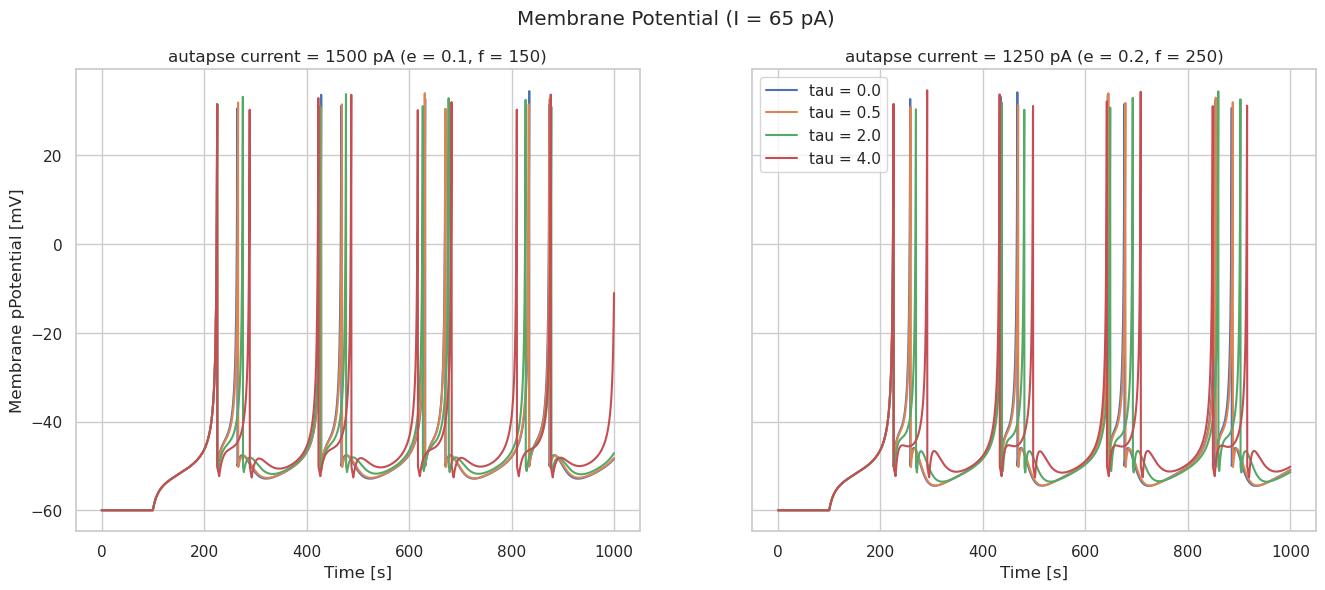

In [ ]:
fig, ax = plt.subplots(1, 2, figsize = (16, 6), sharey = True)

for i in range(len(tau_vals)):
    label = f"tau = {tau_vals[i]}"
    ax[0].plot(T, X_1500[i, 0, :], label = label)
    ax[1].plot(T, X_1250[i, 0, :], label = label)

ax[0].set_xlabel("Time [s]")
ax[0].set_ylabel("Membrane pPotential [mV]")

ax[1].set_xlabel('Time [s]')

ax[0].set_title('autapse current = 1500 pA (e = 0.1, f = 150)')
ax[1].set_title('autapse current = 1250 pA (e = 0.2, f = 250)')

fig.suptitle(f"Membrane Potential (I = {I_h} pA)")
plt.legend()

#plt.savefig(out_dir + "membrane_potentials_diffTau.png")

In [ ]:
"""
Now 2 sets of identical neurons with different driving frequencies


"""


params = df[((df['autapse current'] == 1250.0) | (df['autapse current'] == 1500.0)) & (df['I_h'] == 0.0)]

RS_int = {'name': 'RS_ref', 'C': 100, 'k': 0.7, 'v_r': -60, 'v_t': -40, 'v_peak': 35,
     'a': 0.03, 'b': -2, 'c': -50, 'd': 100, 'e': 0., 'f': 0., 'tau': 0.}

RS_int_1500 = {'name': 'RS_ref', 'C': 100, 'k': 0.7, 'v_r': -60, 'v_t': -40, 'v_peak': 35,
     'a': 0.03, 'b': -2, 'c': -50, 'd': 100, 'e': 0.1, 'f': 150., 'tau': 0.}
    
RS_int_1250 = {'name': 'RS_ref', 'C': 100, 'k': 0.7, 'v_r': -60, 'v_t': -40, 'v_peak': 35,
     'a': 0.03, 'b': -2, 'c': -50, 'd': 100, 'e': 0.2, 'f': 250., 'tau': 0.}



params_1500 = []
params_1250 = []

I_range = np.linspace(50, 110, 7)

for I in I_range:
    params_1500.append(RS_int_1500)
    params_1250.append(RS_int_1250)


df_1500 = pd.DataFrame(params_1500)
df_1250 = pd.DataFrame(params_1250)

#sim params
T = 1000
dt = 0.1
N_iter = int(T/dt)

batch_1500 = batchAQUA(df_1500)
batch_1250 = batchAQUA(df_1250)

x_start = np.full((len(I_range), 3), fill_value = np.array([-60, 0, 0]))
t_start = np.zeros(len(I_range))

batch_1500.Initialise(x_start, t_start)
batch_1250.Initialise(x_start, t_start)

# define injected current 
I_inj = np.array([step_current(N_iter, dt, 0.0, 100, i) for i in I_range])

# simulate
X_1500, T, spikes_1500 = batch_1500.update_batch(dt, N_iter, I_inj)
X_1250, T, spikes_1250 = batch_1250.update_batch(dt, N_iter, I_inj)

100%|██████████| 9999/9999 [00:01<00:00, 7921.60it/s]


Text(0.5, 0.98, 'Neuron trace with different driving currents')

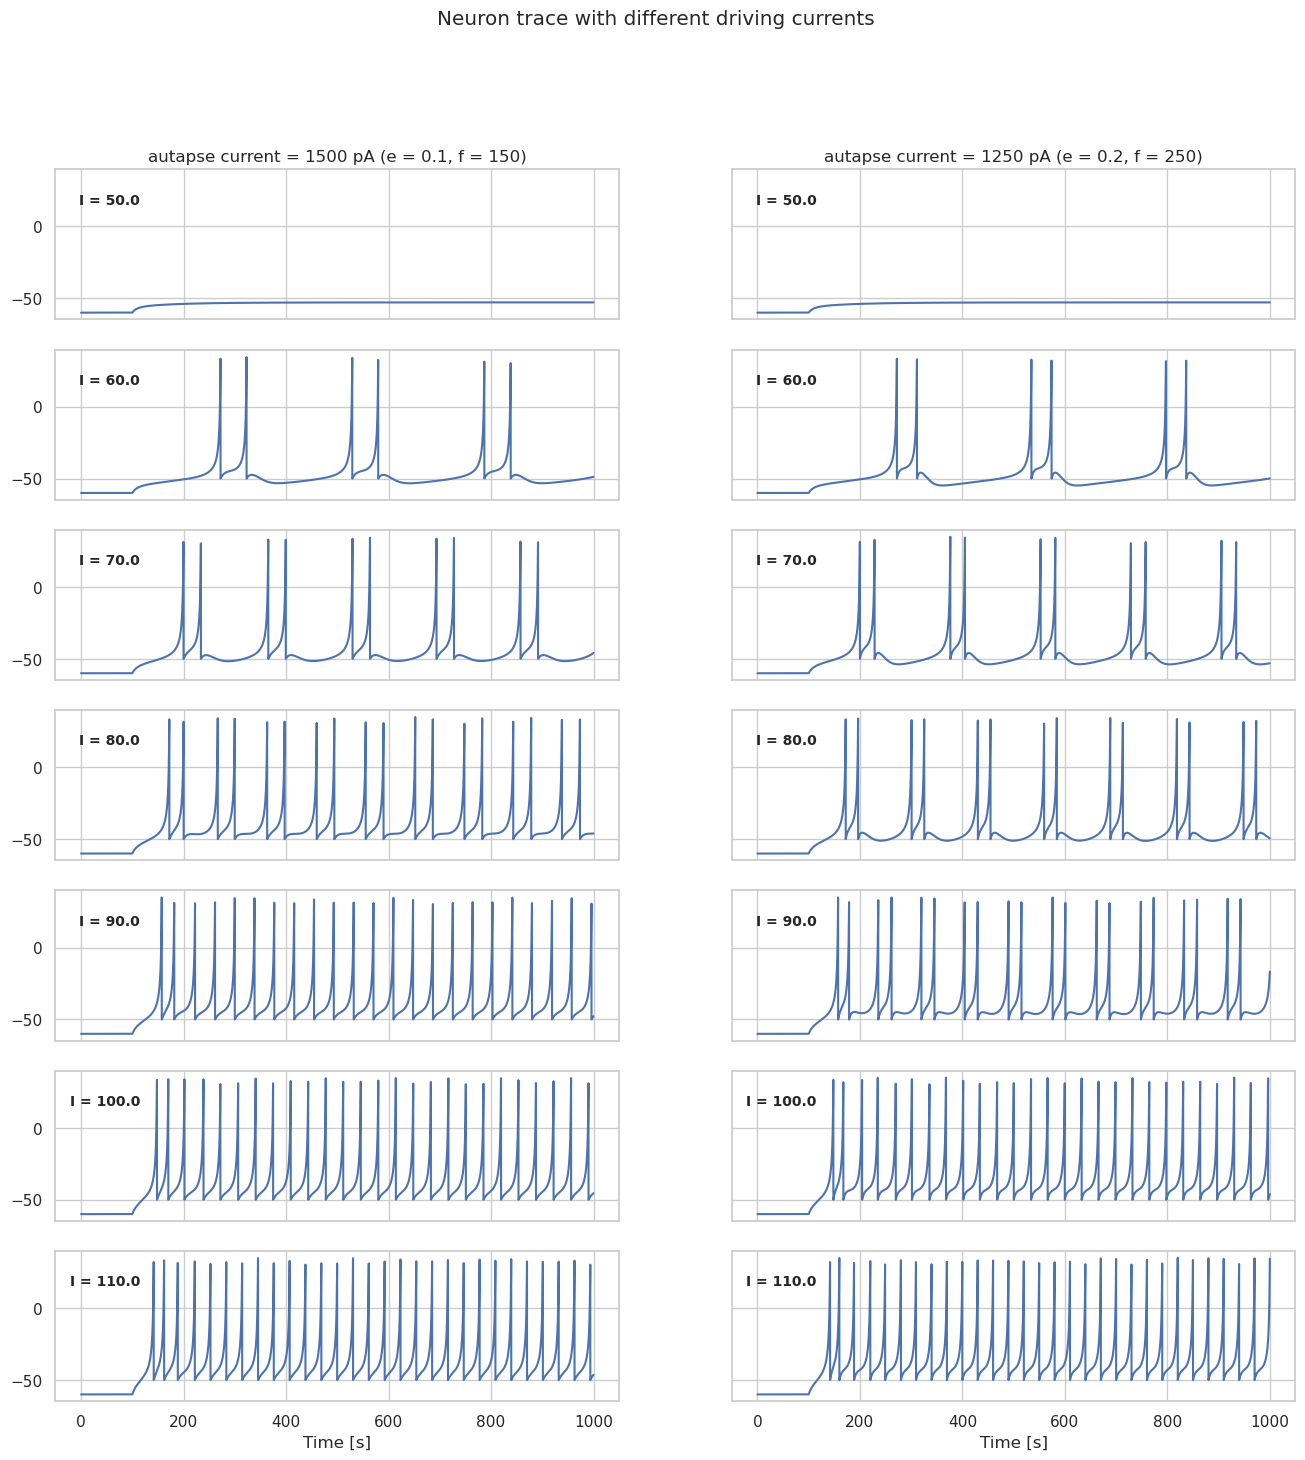

In [ ]:
fig, ax = plt.subplots(len(I_range), 2, figsize = (16, 16), sharey = True, sharex = True)

for n, i in enumerate(I_range):
    label = f"I = {I_range[n]}"
    ax[n, 0].plot(T, X_1500[n, 0, :], label = label)
    ax[n, 1].plot(T, X_1250[n, 0, :], label = label)

    ax[n, 0].text(0.15, 0.75, label, verticalalignment = 'bottom', horizontalalignment = 'right',
            transform = ax[n, 0].transAxes, fontsize = 10, fontweight = 'bold')
    ax[n, 1].text(0.15, 0.75, label, verticalalignment = 'bottom', horizontalalignment = 'right',
            transform = ax[n, 1].transAxes, fontsize = 10, fontweight = 'bold')
    #ax[n, 0].set_ylabel(label)

ax[n, 0].set_xlabel("Time [s]")

ax[n, 1].set_xlabel('Time [s]')

ax[0, 0].set_title('autapse current = 1500 pA (e = 0.1, f = 150)')
ax[0, 1].set_title('autapse current = 1250 pA (e = 0.2, f = 250)')

fig.suptitle("Neuron trace with different driving currents")

#plt.savefig(out_dir + "membrane_potentials_diffI.png")

In [ ]:
"""
Now 2 sets of identical neurons with different driving frequencies


"""

RS_int = {'name': 'RS_ref', 'C': 100, 'k': 0.7, 'v_r': -60, 'v_t': -40, 'v_peak': 35,
     'a': 0.03, 'b': -2, 'c': -50, 'd': 100, 'e': 0., 'f': 0., 'tau': 0.}

RS_int_1500 = {'name': 'RS_ref', 'C': 100, 'k': 0.7, 'v_r': -60, 'v_t': -40, 'v_peak': 35,
     'a': 0.03, 'b': -2, 'c': -50, 'd': 100, 'e': 0.1, 'f': 150., 'tau': 0.}
    
RS_int_900 = {'name': 'RS_ref', 'C': 100, 'k': 0.7, 'v_r': -60, 'v_t': -40, 'v_peak': 35,
     'a': 0.03, 'b': -2, 'c': -50, 'd': 100, 'e': 0.2, 'f': 180., 'tau': 0.}

params = [RS_int, RS_int_1500, RS_int_900]


df = pd.DataFrame(params)

T = 1000
dt = 0.1
N_iter = int(T/dt)

batch = batchAQUA(df)

x_start = np.full((3, 3), fill_value = np.array([-60, 0, 0]))
t_start = np.zeros(3)

batch.Initialise(x_start, t_start)

# define injected current 
I_h = 65
I_inj = np.array([step_current(N_iter, dt, 0.0, 100, I_h) for _ in range(3)])

# simulate
X, T, spikes= batch.update_batch(dt, N_iter, I_inj)



100%|██████████| 9999/9999 [00:01<00:00, 7833.65it/s]


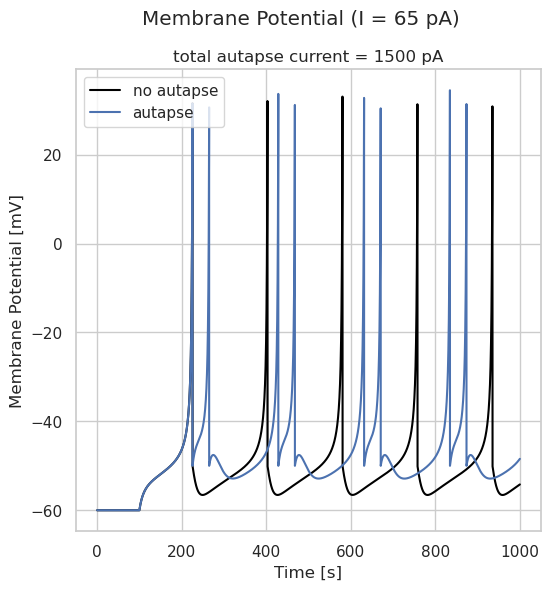

In [ ]:
fig, ax = plt.subplots(1, 1, figsize = (6, 6))

ax.plot(T, X[0, 0, :], c = 'black', label = 'no autapse')
ax.plot(T, X[1, 0, :], label = 'autapse')
#ax.plot(T, X[2, 0, :], label = 'autapse')

ax.set_ylabel("Membrane Potential [mV]")
ax.set_xlabel('Time [s]')

ax.set_title('total autapse current = 1500 pA')

fig.suptitle(f"Membrane Potential (I = {I_h} pA)")
plt.legend()

#plt.savefig(out_dir + "membrane_potentials_diffTau.png")